# 20 Regression Models, 20 Different Graphs

Each model gets its **own diagnostic plot** that shows something specific to how that model works.
At the end there is a comparison dashboard of all models.

**Install once:** `pip install numpy pandas matplotlib seaborn scikit-learn xgboost lightgbm catboost`

In [69]:
import warnings, re, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, validation_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.tree import plot_tree

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import (LinearRegression, RidgeCV, LassoCV, ElasticNetCV,
                                  BayesianRidge, HuberRegressor, SGDRegressor)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, AdaBoostRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42

## 1. Load your data
Set `DATA_PATH` (CSV or Excel) and `TARGET` (the column to predict).

In [70]:
DATA_PATH = None          # e.g. "my_data.csv"  -> leave None to use the demo dataset
TARGET    = "target"      # name of your target column

if DATA_PATH:
    df = pd.read_excel(DATA_PATH) if DATA_PATH.endswith((".xlsx", ".xls")) else pd.read_csv(DATA_PATH)
else:
    from sklearn.datasets import load_diabetes
    df = load_diabetes(as_frame=True).frame.rename(columns={"target": TARGET})

df = df.dropna(subset=[TARGET])
print(df.shape); display(df.head())

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2. Preprocessing and train/test split

In [71]:
X, y = df.drop(columns=[TARGET]), df[TARGET].astype(float)
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
])
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
clean = lambda n: re.sub(r"[^0-9a-zA-Z_]", "_", n)
cols = [clean(c) for c in pre.fit(X_tr_raw).get_feature_names_out()]
X_tr = pd.DataFrame(pre.transform(X_tr_raw), columns=cols, index=X_tr_raw.index)
X_te = pd.DataFrame(pre.transform(X_te_raw), columns=cols, index=X_te_raw.index)
print("Train:", X_tr.shape, "Test:", X_te.shape)

results, preds, fitted = {}, {}, {}

def run(name, model, **fit_kw):
    t = time.time(); model.fit(X_tr, y_tr, **fit_kw); dt = time.time() - t
    p = model.predict(X_te)
    results[name] = dict(RMSE=np.sqrt(mean_squared_error(y_te, p)), MAE=mean_absolute_error(y_te, p),
                         R2=r2_score(y_te, p), FitTime=dt)
    preds[name], fitted[name] = p, model
    print(f"{name:28s} RMSE={results[name]['RMSE']:.3f}  MAE={results[name]['MAE']:.3f}  R2={results[name]['R2']:.3f}")
    return p

def top_features(imp, n=10):
    return pd.Series(imp, index=cols).sort_values(ascending=False).head(n)[::-1]

Train: (353, 10) Test: (89, 10)


## 1) Dummy mean baseline: *target distribution vs constant prediction*

Dummy mean baseline          RMSE=73.222  MAE=64.006  R2=-0.012


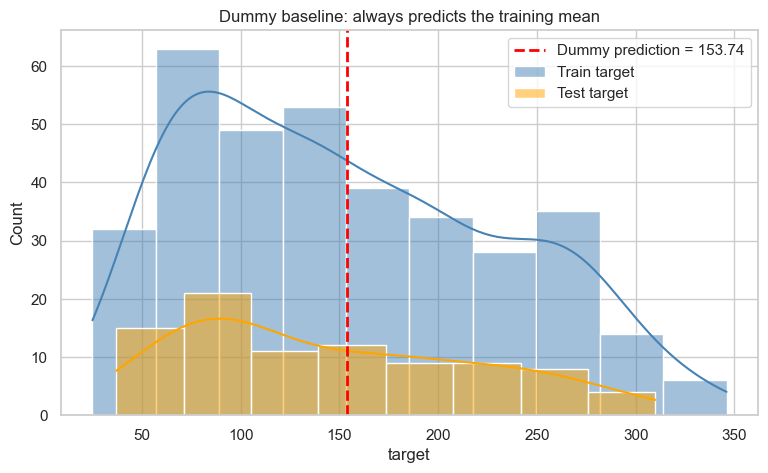

In [72]:
p = run("Dummy mean baseline", DummyRegressor(strategy="mean"))
fig, ax = plt.subplots()
sns.histplot(y_tr, kde=True, color="steelblue", label="Train target", ax=ax)
sns.histplot(y_te, kde=True, color="orange", label="Test target", alpha=.5, ax=ax)
ax.axvline(p[0], color="red", ls="--", lw=2, label=f"Dummy prediction = {p[0]:.2f}")
ax.set(title="Dummy baseline: always predicts the training mean", xlabel=TARGET); ax.legend(); plt.show()

## 2) Linear Regression: *actual vs predicted*

Linear Regression            RMSE=53.853  MAE=42.794  R2=0.453


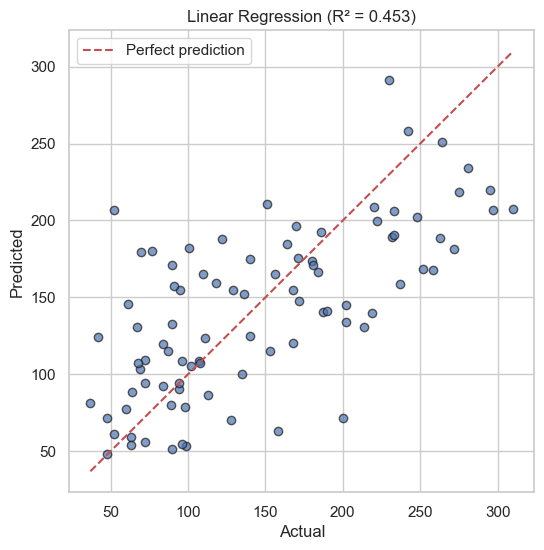

In [73]:
p = run("Linear Regression", LinearRegression())
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_te, p, alpha=.7, edgecolor="k"); lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
ax.plot(lim, lim, "r--", label="Perfect prediction"); ax.set(xlabel="Actual", ylabel="Predicted",
    title=f"Linear Regression (R² = {results['Linear Regression']['R2']:.3f})"); ax.legend(); plt.show()

## 3) Ridge: *coefficient shrinkage path*

Ridge                        RMSE=53.767  MAE=42.815  R2=0.454


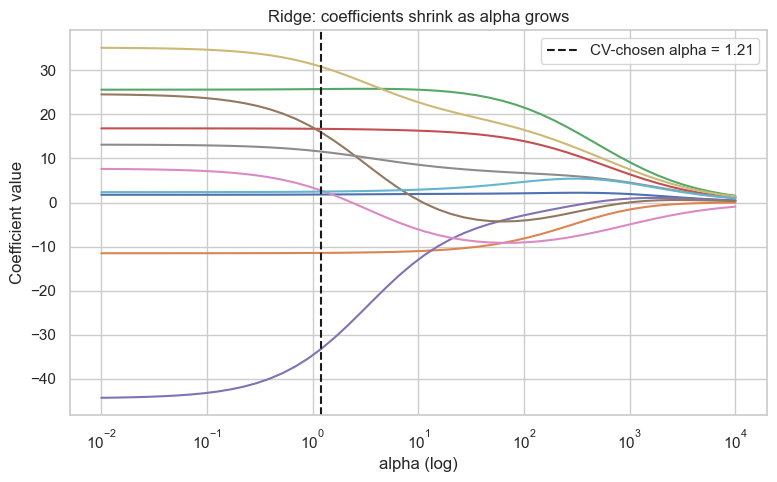

In [74]:
from sklearn.linear_model import Ridge
alphas = np.logspace(-2, 4, 50)
coefs = [Ridge(alpha=a).fit(X_tr, y_tr).coef_ for a in alphas]
p = run("Ridge", RidgeCV(alphas=alphas))
fig, ax = plt.subplots()
ax.plot(alphas, coefs); ax.set_xscale("log")
ax.axvline(fitted["Ridge"].alpha_, color="k", ls="--", label=f"CV-chosen alpha = {fitted['Ridge'].alpha_:.2f}")
ax.set(xlabel="alpha (log)", ylabel="Coefficient value", title="Ridge: coefficients shrink as alpha grows"); ax.legend(); plt.show()

## 4) Lasso: *coefficient path (features dropping to zero)*

Lasso                        RMSE=52.920  MAE=42.793  R2=0.471


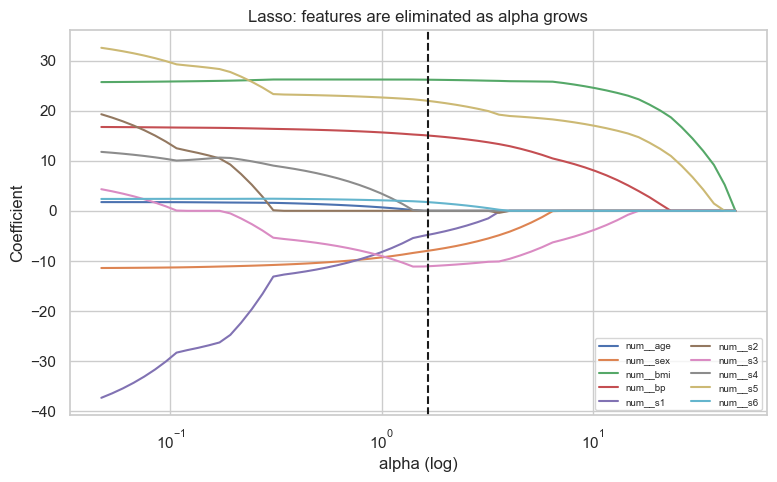

In [75]:
from sklearn.linear_model import lasso_path
a_path, c_path, _ = lasso_path(X_tr, y_tr, n_alphas=60)
p = run("Lasso", LassoCV(cv=5, random_state=RANDOM_STATE))
fig, ax = plt.subplots()
for c, name in zip(c_path, cols): ax.plot(a_path, c, label=name)
ax.set_xscale("log"); ax.axvline(fitted["Lasso"].alpha_, color="k", ls="--")
ax.set(xlabel="alpha (log)", ylabel="Coefficient", title="Lasso: features are eliminated as alpha grows")
if len(cols) <= 12: ax.legend(fontsize=7, ncol=2)
plt.show()

## 5) ElasticNet: *CV error heatmap (alpha × l1_ratio)*

ElasticNet                   RMSE=53.446  MAE=42.981  R2=0.461


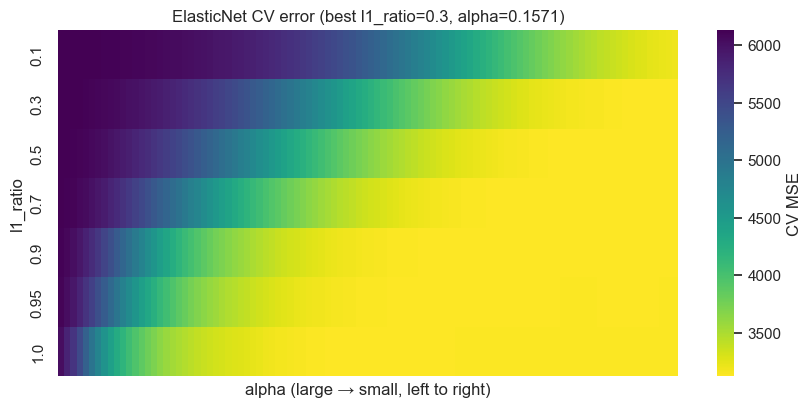

In [76]:
l1s = [.1, .3, .5, .7, .9, .95, 1.0]
p = run("ElasticNet", ElasticNetCV(l1_ratio=l1s, cv=5, random_state=RANDOM_STATE))
en = fitted["ElasticNet"]
mse = en.mse_path_.mean(axis=2)                     # (l1_ratio, alpha)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(mse, ax=ax, cmap="viridis_r", yticklabels=l1s, xticklabels=False, cbar_kws={"label": "CV MSE"})
ax.set(xlabel="alpha (large → small, left to right)", ylabel="l1_ratio",
       title=f"ElasticNet CV error (best l1_ratio={en.l1_ratio_}, alpha={en.alpha_:.4f})"); plt.show()

## 6) Bayesian Ridge: *predictions with uncertainty band*

Bayesian Ridge               RMSE=53.591  MAE=42.870  R2=0.458


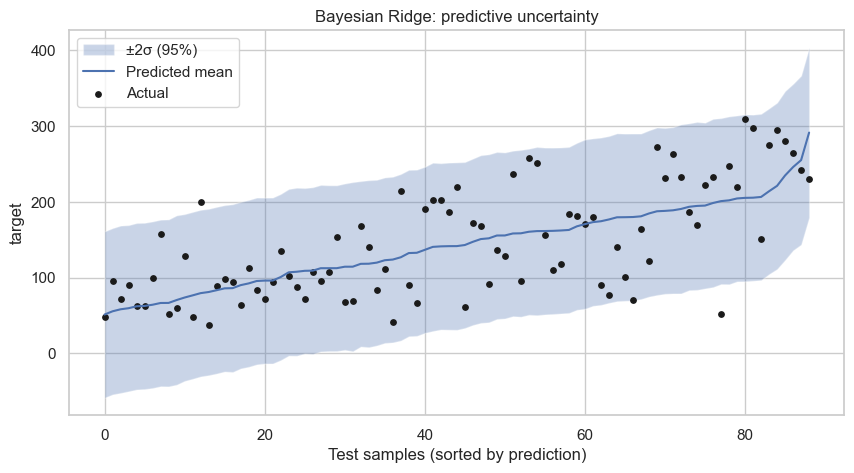

In [77]:
run("Bayesian Ridge", BayesianRidge())
mu, sd = fitted["Bayesian Ridge"].predict(X_te, return_std=True)

# convert to plain NumPy arrays so [o] indexes by position, not by pandas label
mu = np.asarray(mu, dtype=float)
sd = np.asarray(sd, dtype=float)
y_arr = np.asarray(y_te, dtype=float)

o = np.argsort(mu)
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(range(len(o)), (mu - 2*sd)[o], (mu + 2*sd)[o], alpha=.3, label="±2σ (95%)")
ax.plot(mu[o], "b-", label="Predicted mean")
ax.scatter(range(len(o)), y_arr[o], c="k", s=15, label="Actual")
ax.set(xlabel="Test samples (sorted by prediction)", ylabel=TARGET,
       title="Bayesian Ridge: predictive uncertainty")
ax.legend(); plt.show()

## 7) Huber Regressor: *outlier handling (residuals vs OLS)*

Huber Regressor              RMSE=54.137  MAE=42.880  R2=0.447


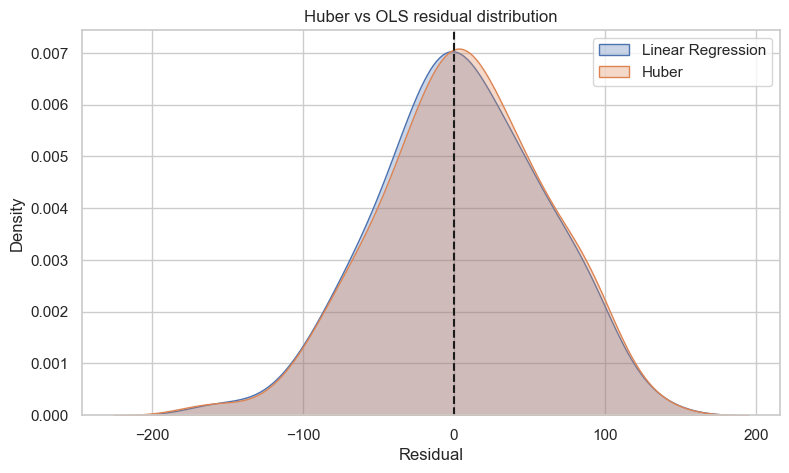

In [78]:
run("Huber Regressor", HuberRegressor(max_iter=2000))
res_h = y_te - preds["Huber Regressor"]; res_l = y_te - preds["Linear Regression"]
fig, ax = plt.subplots()
sns.kdeplot(res_l, label="Linear Regression", fill=True, alpha=.3, ax=ax)
sns.kdeplot(res_h, label="Huber", fill=True, alpha=.3, ax=ax)
ax.axvline(0, color="k", ls="--"); ax.set(xlabel="Residual", title="Huber vs OLS residual distribution"); ax.legend(); plt.show()

## 8) SGD Regressor: *loss per epoch*

{'RMSE': np.float64(54.411422229762096), 'MAE': 43.282280947572914, 'R2': 0.4412008168897067, 'FitTime': nan}


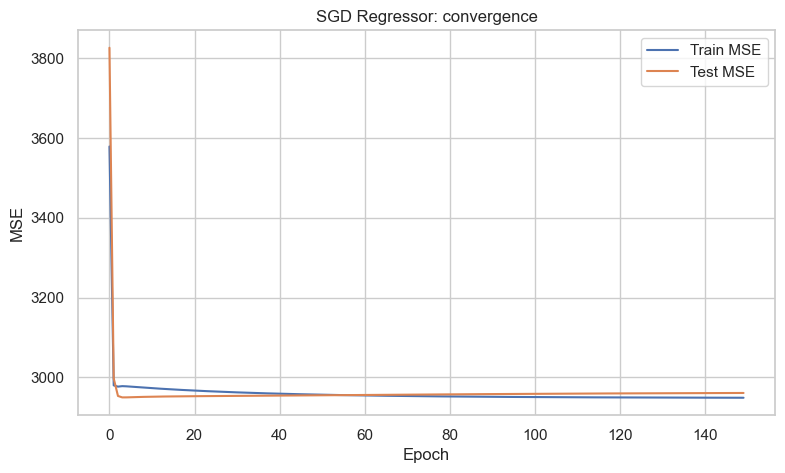

In [79]:
sgd = SGDRegressor(learning_rate="constant", eta0=0.005, random_state=RANDOM_STATE)
tr_l, te_l = [], []
for _ in range(150):
    sgd.partial_fit(X_tr, y_tr)
    tr_l.append(mean_squared_error(y_tr, sgd.predict(X_tr))); te_l.append(mean_squared_error(y_te, sgd.predict(X_te)))
p = sgd.predict(X_te)
results["SGD Regressor"] = dict(RMSE=np.sqrt(mean_squared_error(y_te, p)), MAE=mean_absolute_error(y_te, p),
                                R2=r2_score(y_te, p), FitTime=np.nan)
preds["SGD Regressor"], fitted["SGD Regressor"] = p, sgd
print(results["SGD Regressor"])
fig, ax = plt.subplots(); ax.plot(tr_l, label="Train MSE"); ax.plot(te_l, label="Test MSE")
ax.set(xlabel="Epoch", ylabel="MSE", title="SGD Regressor: convergence"); ax.legend(); plt.show()

## 9) Decision Tree: *the tree itself*

Decision Tree                RMSE=57.985  MAE=46.773  R2=0.365


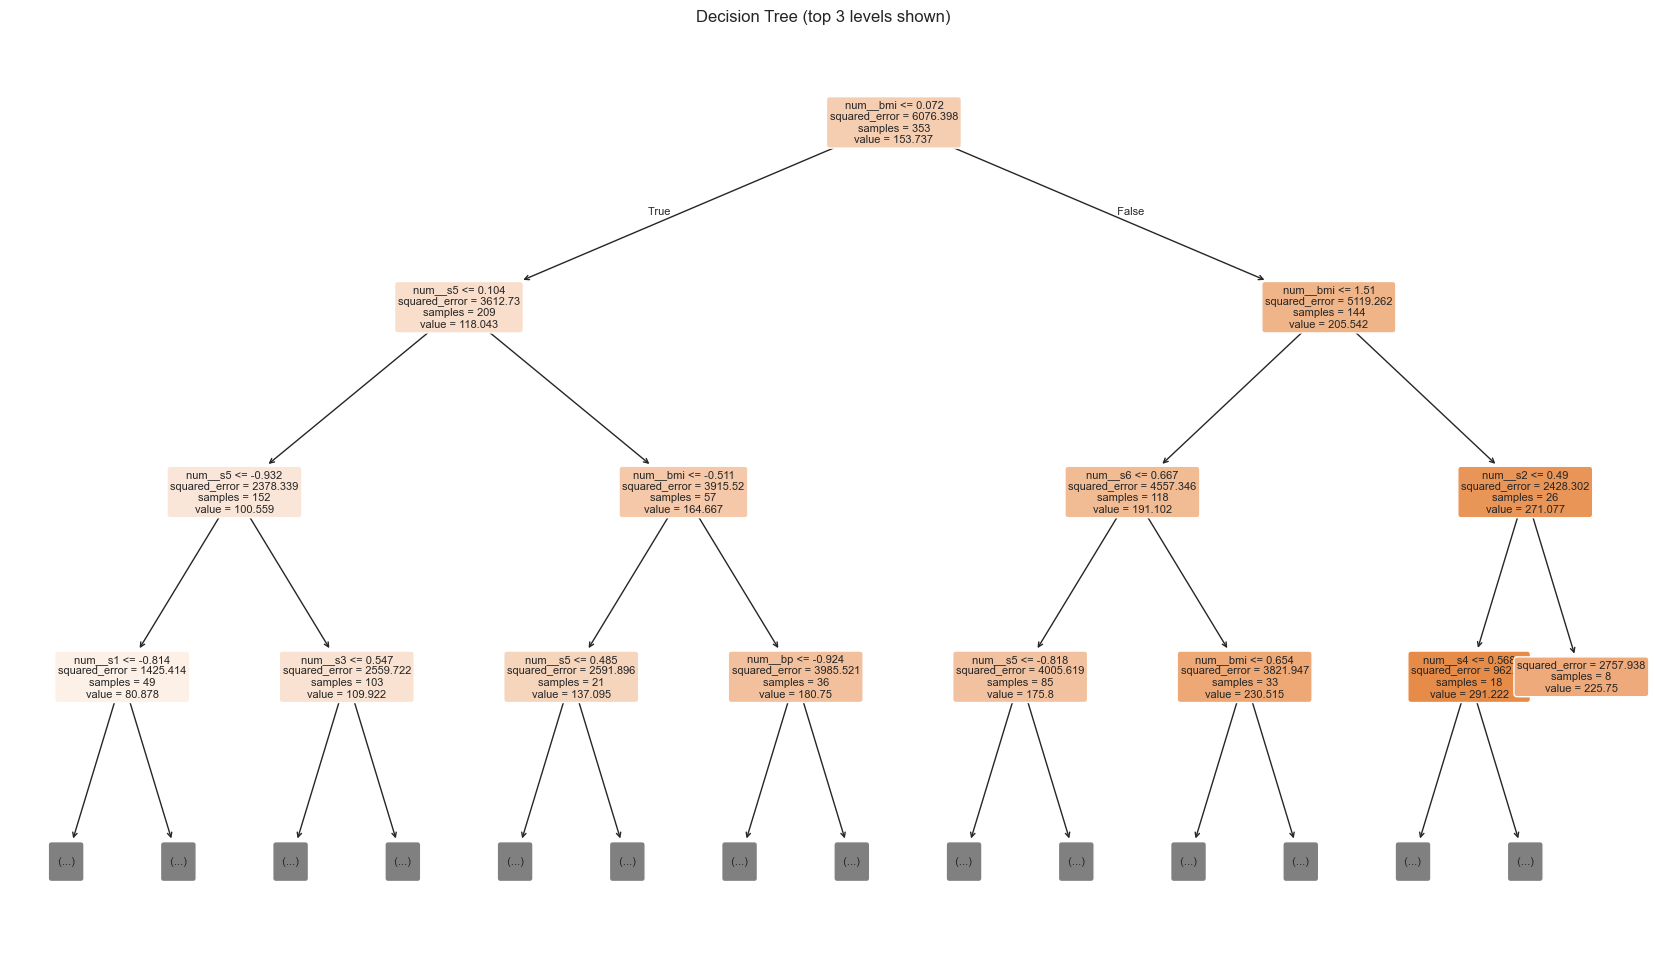

In [97]:
run("Decision Tree", DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=RANDOM_STATE))
fig, ax = plt.subplots(figsize=(21, 12))
plot_tree(fitted["Decision Tree"], feature_names=cols, filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title("Decision Tree (top 3 levels shown)"); plt.show()

## 10) Random Forest: *feature importance with spread across trees*

Random Forest                RMSE=54.921  MAE=44.752  R2=0.431


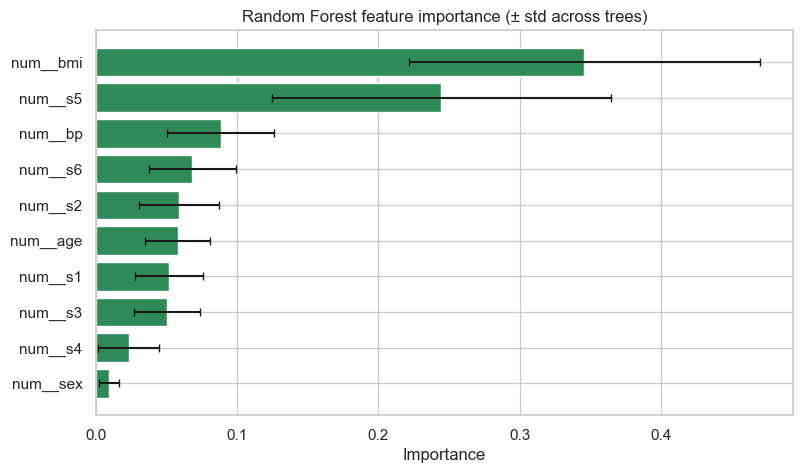

In [81]:
run("Random Forest", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
rf = fitted["Random Forest"]
std = np.std([t.feature_importances_ for t in rf.estimators_], axis=0)
imp = pd.Series(rf.feature_importances_, index=cols); err = pd.Series(std, index=cols)
top = imp.sort_values(ascending=False).head(12)[::-1]
fig, ax = plt.subplots(); ax.barh(top.index, top.values, xerr=err[top.index], color="seagreen", capsize=3)
ax.set(title="Random Forest feature importance (± std across trees)", xlabel="Importance"); plt.show()

## 11) Extra Trees: *permutation importance boxplot*

Extra Trees                  RMSE=53.050  MAE=43.859  R2=0.469


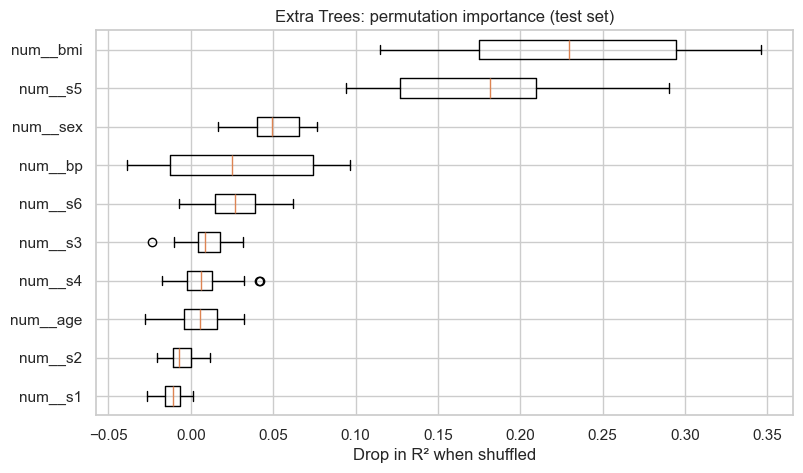

In [82]:
run("Extra Trees", ExtraTreesRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
pi = permutation_importance(fitted["Extra Trees"], X_te, y_te, n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
idx = pi.importances_mean.argsort()[-12:]
fig, ax = plt.subplots(); ax.boxplot(pi.importances[idx].T, vert=False, labels=np.array(cols)[idx])
ax.set(title="Extra Trees: permutation importance (test set)", xlabel="Drop in R² when shuffled"); plt.show()

## 12) Gradient Boosting: *train vs test deviance by stage*

Gradient Boosting            RMSE=53.386  MAE=43.617  R2=0.462


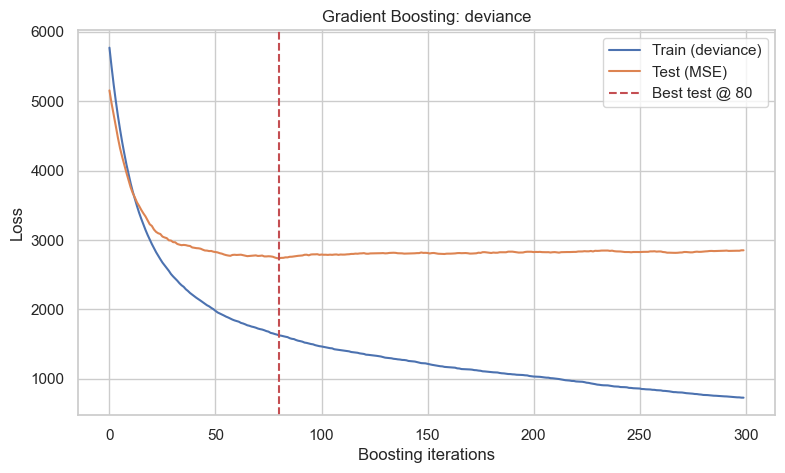

In [83]:
run("Gradient Boosting", GradientBoostingRegressor(n_estimators=300, learning_rate=.05, max_depth=3, random_state=RANDOM_STATE))
gb = fitted["Gradient Boosting"]
te_dev = [mean_squared_error(y_te, p_) for p_ in gb.staged_predict(X_te)]
fig, ax = plt.subplots(); ax.plot(gb.train_score_, label="Train (deviance)"); ax.plot(te_dev, label="Test (MSE)")
ax.axvline(np.argmin(te_dev), color="r", ls="--", label=f"Best test @ {np.argmin(te_dev)}")
ax.set(xlabel="Boosting iterations", ylabel="Loss", title="Gradient Boosting: deviance"); ax.legend(); plt.show()

## 13) Hist Gradient Boosting: *test R² by iteration*

Hist Gradient Boosting       RMSE=57.862  MAE=46.070  R2=0.368


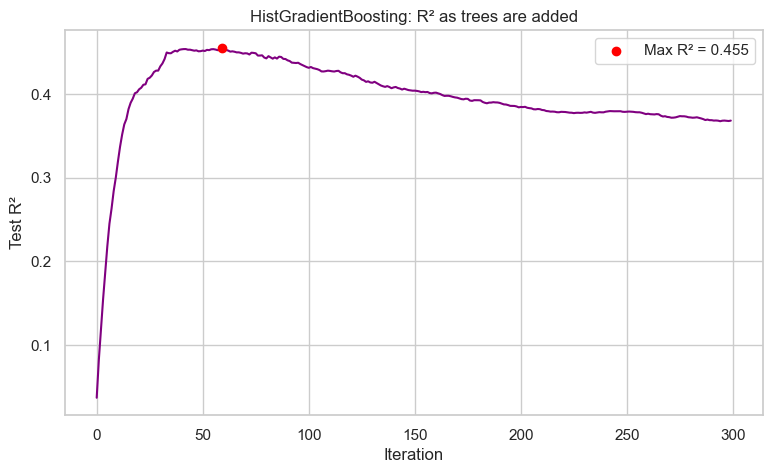

In [84]:
run("Hist Gradient Boosting", HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, random_state=RANDOM_STATE))
h = fitted["Hist Gradient Boosting"]
r2s = [r2_score(y_te, p_) for p_ in h.staged_predict(X_te)]
fig, ax = plt.subplots(); ax.plot(r2s, color="purple")
ax.scatter(np.argmax(r2s), max(r2s), color="red", zorder=5, label=f"Max R² = {max(r2s):.3f}")
ax.set(xlabel="Iteration", ylabel="Test R²", title="HistGradientBoosting: R² as trees are added"); ax.legend(); plt.show()

## 14) AdaBoost: *staged R² and per-estimator weights*

AdaBoost                     RMSE=54.111  MAE=43.760  R2=0.447


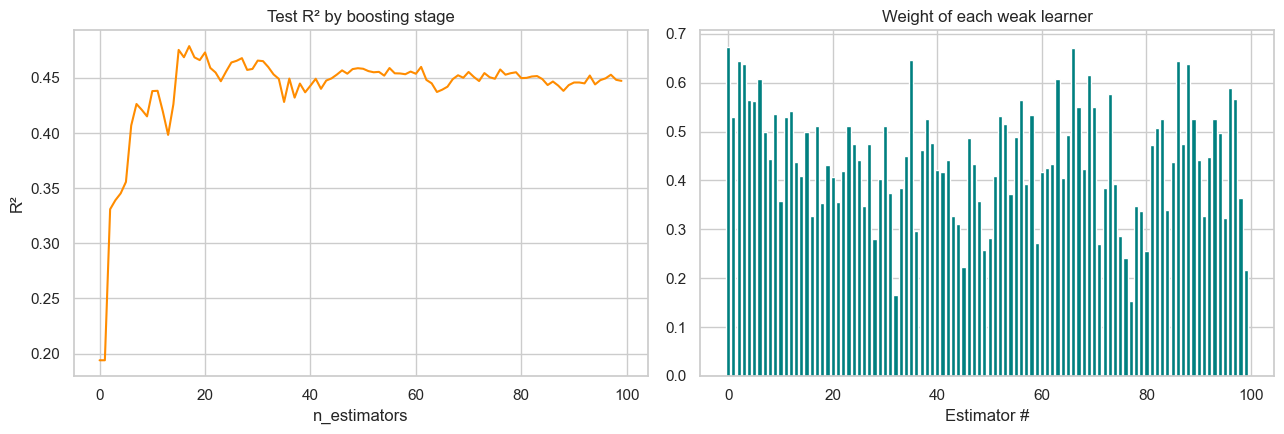

In [85]:
run("AdaBoost", AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), n_estimators=100, learning_rate=.5, random_state=RANDOM_STATE))
ab = fitted["AdaBoost"]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot([r2_score(y_te, p_) for p_ in ab.staged_predict(X_te)], color="darkorange")
axs[0].set(title="Test R² by boosting stage", xlabel="n_estimators", ylabel="R²")
axs[1].bar(range(len(ab.estimator_weights_)), ab.estimator_weights_, color="teal")
axs[1].set(title="Weight of each weak learner", xlabel="Estimator #"); plt.tight_layout(); plt.show()

## 15) K-Nearest Neighbors: *CV error vs k*

K-Nearest Neighbors          RMSE=55.299  MAE=45.657  R2=0.423


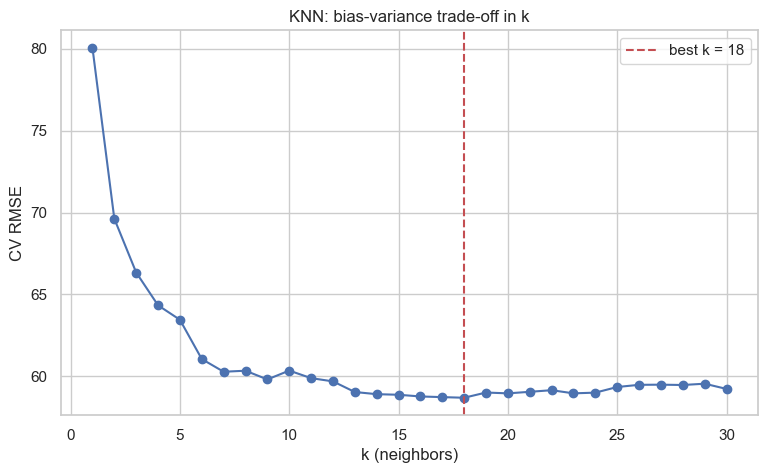

In [86]:
ks = range(1, 31)
cv_rmse = [-cross_val_score(KNeighborsRegressor(k), X_tr, y_tr, cv=5, scoring="neg_root_mean_squared_error").mean() for k in ks]
best_k = list(ks)[int(np.argmin(cv_rmse))]
run("K-Nearest Neighbors", KNeighborsRegressor(n_neighbors=best_k))
fig, ax = plt.subplots(); ax.plot(ks, cv_rmse, "o-"); ax.axvline(best_k, color="r", ls="--", label=f"best k = {best_k}")
ax.set(xlabel="k (neighbors)", ylabel="CV RMSE", title="KNN: bias-variance trade-off in k"); ax.legend(); plt.show()

## 16) Support Vector Regression: *validation curve over C*

Support Vector Regression    RMSE=50.103  MAE=39.103  R2=0.526


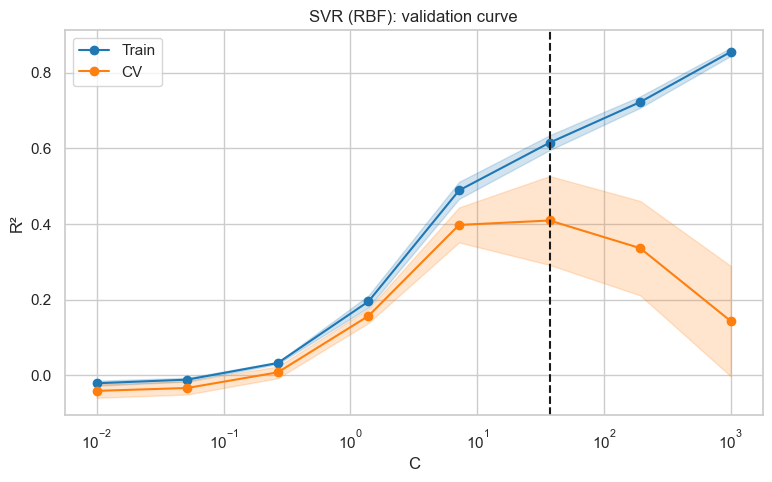

In [87]:
Cs = np.logspace(-2, 3, 8)
tr_s, cv_s = validation_curve(SVR(kernel="rbf"), X_tr, y_tr, param_name="C", param_range=Cs, cv=5, scoring="r2")
bestC = Cs[cv_s.mean(1).argmax()]
run("Support Vector Regression", SVR(kernel="rbf", C=bestC))
fig, ax = plt.subplots()
for s, lab, c in [(tr_s, "Train", "tab:blue"), (cv_s, "CV", "tab:orange")]:
    ax.plot(Cs, s.mean(1), "o-", label=lab, color=c); ax.fill_between(Cs, s.mean(1)-s.std(1), s.mean(1)+s.std(1), alpha=.2, color=c)
ax.set_xscale("log"); ax.axvline(bestC, color="k", ls="--"); ax.set(xlabel="C", ylabel="R²", title="SVR (RBF): validation curve"); ax.legend(); plt.show()

## 17) MLP Neural Network: *training loss & validation score*

MLP Neural Network           RMSE=60.471  MAE=48.161  R2=0.310


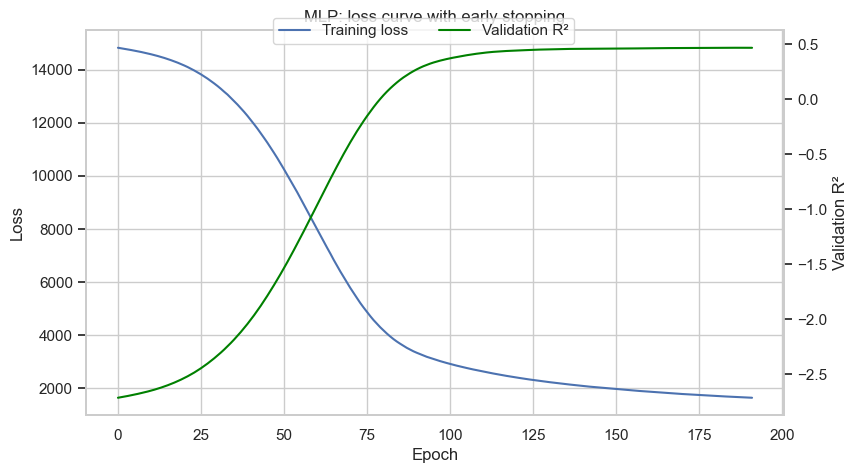

In [88]:
run("MLP Neural Network", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, early_stopping=True, random_state=RANDOM_STATE))
m = fitted["MLP Neural Network"]
fig, ax = plt.subplots(); ax.plot(m.loss_curve_, label="Training loss")
ax2 = ax.twinx(); ax2.plot(m.validation_scores_, color="green", label="Validation R²"); ax2.grid(False)
ax.set(xlabel="Epoch", ylabel="Loss", title="MLP: loss curve with early stopping"); ax2.set_ylabel("Validation R²")
fig.legend(loc="upper center", ncol=2, bbox_to_anchor=(.5, .92)); plt.show()

## 18) XGBoost: *learning curve (RMSE per round)*

XGBoost                      RMSE=56.770  MAE=45.536  R2=0.392


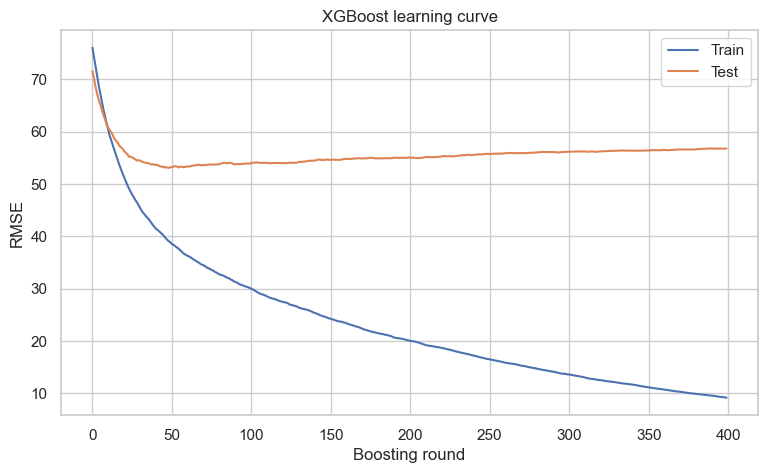

In [89]:
run("XGBoost", XGBRegressor(n_estimators=400, learning_rate=.05, max_depth=4, subsample=.8, colsample_bytree=.8,
                            eval_metric="rmse", random_state=RANDOM_STATE),
    eval_set=[(X_tr, y_tr), (X_te, y_te)], verbose=False)
ev = fitted["XGBoost"].evals_result()
fig, ax = plt.subplots(); ax.plot(ev["validation_0"]["rmse"], label="Train"); ax.plot(ev["validation_1"]["rmse"], label="Test")
ax.set(xlabel="Boosting round", ylabel="RMSE", title="XGBoost learning curve"); ax.legend(); plt.show()

## 19) LightGBM: *feature importance by split count vs gain*

LightGBM                     RMSE=58.093  MAE=47.754  R2=0.363


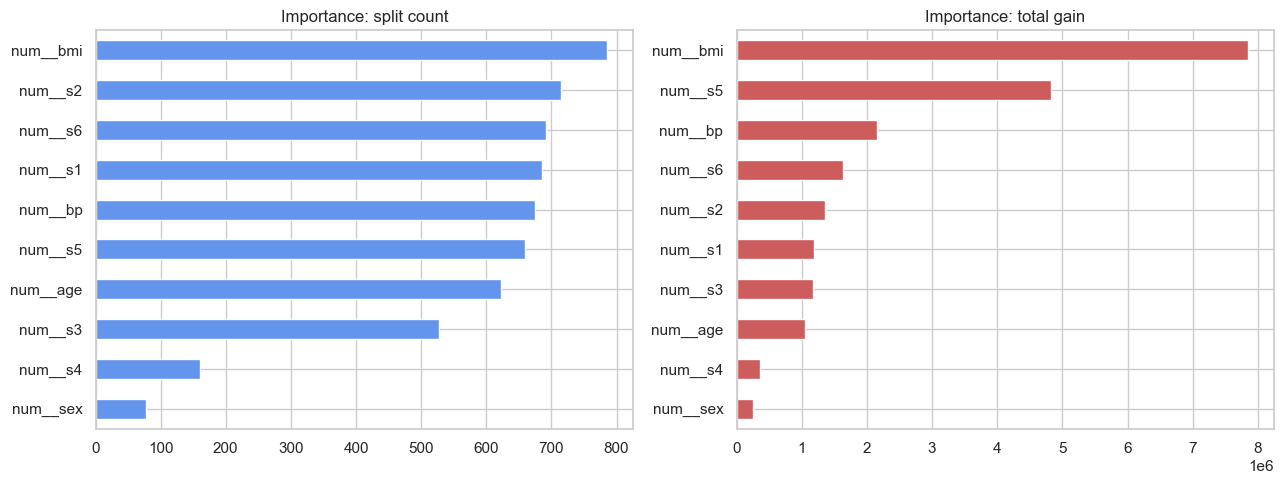

In [90]:
run("LightGBM", LGBMRegressor(n_estimators=400, learning_rate=.05, num_leaves=15, min_child_samples=10,
                              random_state=RANDOM_STATE, verbose=-1))
lg = fitted["LightGBM"]
split = pd.Series(lg.booster_.feature_importance("split"), index=cols)
gain = pd.Series(lg.booster_.feature_importance("gain"), index=cols)
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
split.sort_values().tail(10).plot.barh(ax=axs[0], color="cornflowerblue", title="Importance: split count")
gain.sort_values().tail(10).plot.barh(ax=axs[1], color="indianred", title="Importance: total gain")
plt.tight_layout(); plt.show()

## 20) CatBoost: *partial dependence of the top features*

CatBoost                     RMSE=52.581  MAE=42.610  R2=0.478


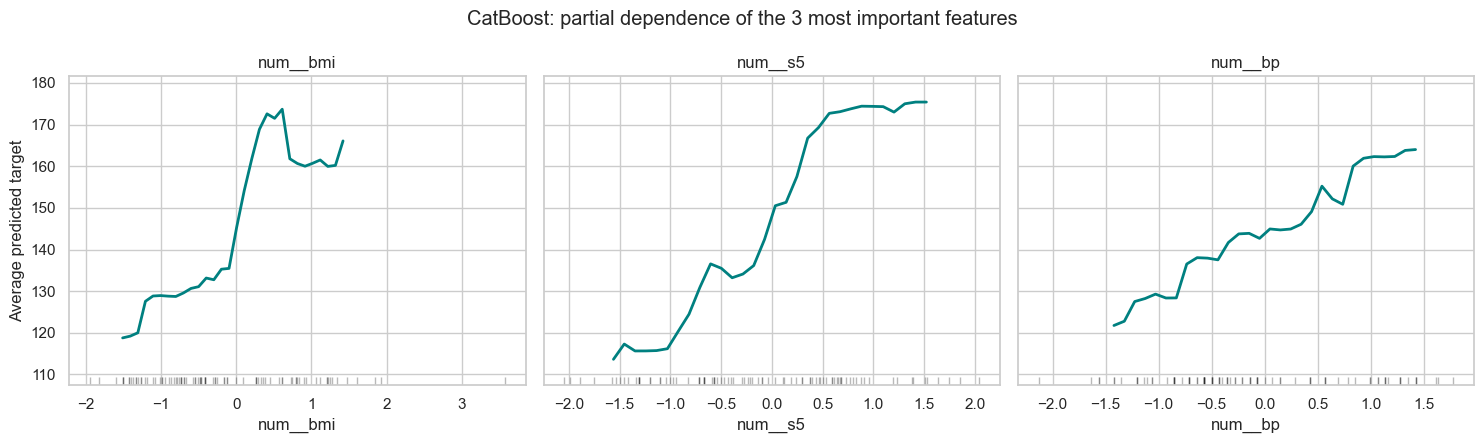

In [91]:
run("CatBoost", CatBoostRegressor(iterations=500, learning_rate=.05, depth=6, verbose=0, random_seed=RANDOM_STATE))
cb = fitted["CatBoost"]
top3 = list(pd.Series(cb.get_feature_importance(), index=cols).sort_values(ascending=False).head(3).index)

def partial_dependence_manual(model, X, feature, n_grid=30):
    grid = np.linspace(X[feature].quantile(.05), X[feature].quantile(.95), n_grid)
    avg = []
    for v in grid:
        Xv = X.copy(); Xv[feature] = v
        avg.append(np.asarray(model.predict(Xv)).mean())
    return grid, np.array(avg)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, f in zip(axs, top3):
    g, a = partial_dependence_manual(cb, X_te, f)
    ax.plot(g, a, lw=2, color="teal")
    sns.rugplot(X_te[f], ax=ax, color="k", alpha=.3)
    ax.set(xlabel=f, title=f)
axs[0].set_ylabel(f"Average predicted {TARGET}")
fig.suptitle("CatBoost: partial dependence of the 3 most important features")
plt.tight_layout(); plt.show()

# Model comparison dashboard

In [92]:
res = pd.DataFrame(results).T.sort_values("RMSE")
display(res.style.background_gradient(cmap="RdYlGn_r", subset=["RMSE", "MAE"]).background_gradient(cmap="RdYlGn", subset=["R2"]).format("{:.3f}"))
print("Models available:", len(res))

,RMSE,MAE,R2,FitTime
Support Vector Regression,50.103,39.103,0.526,0.017
CatBoost,52.581,42.610,0.478,1.184
Lasso,52.920,42.793,0.471,0.077
Extra Trees,53.050,43.859,0.469,0.251
Gradient Boosting,53.386,43.617,0.462,0.812
ElasticNet,53.446,42.981,0.461,0.340
Bayesian Ridge,53.591,42.870,0.458,0.003
Ridge,53.767,42.815,0.454,0.003
Linear Regression,53.853,42.794,0.453,0.004
AdaBoost,54.111,43.760,0.447,0.274


Models available: 20


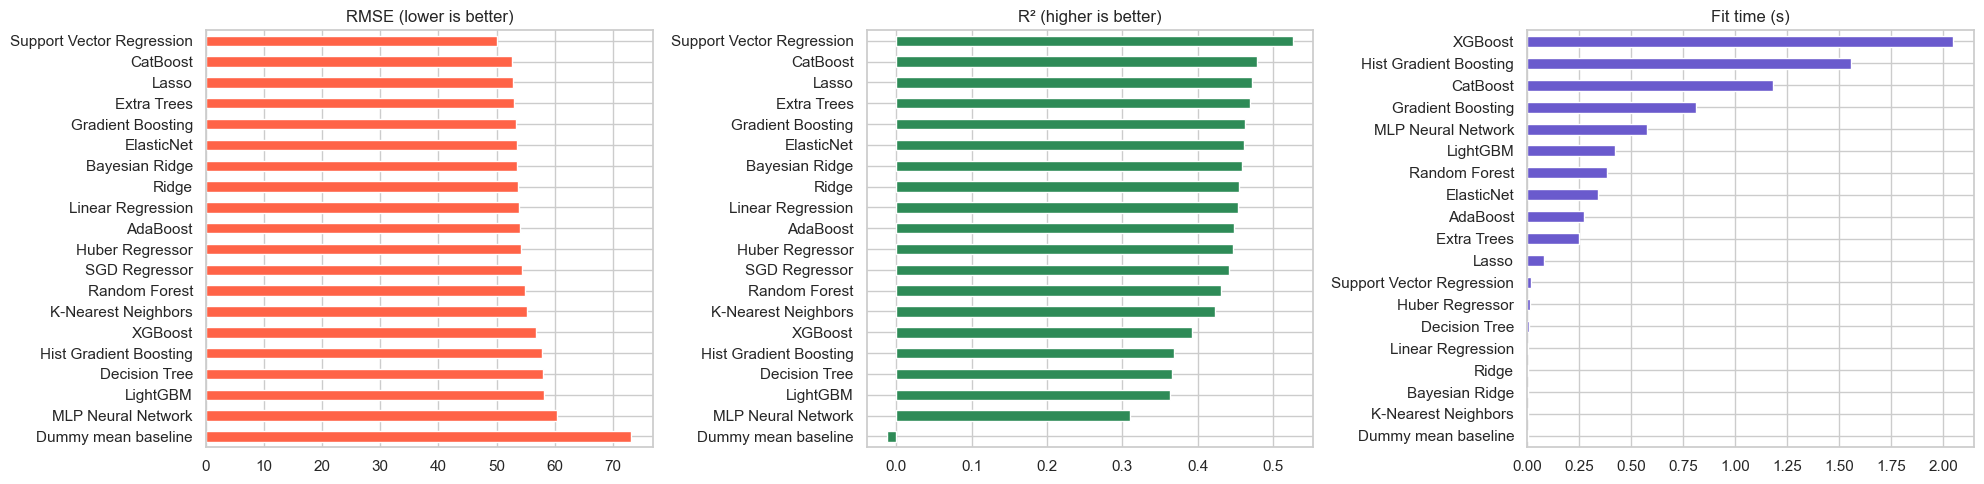

In [93]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
res["RMSE"].sort_values(ascending=False).plot.barh(ax=axs[0], color="tomato", title="RMSE (lower is better)")
res["R2"].sort_values().plot.barh(ax=axs[1], color="seagreen", title="R² (higher is better)")
res["FitTime"].dropna().sort_values().plot.barh(ax=axs[2], color="slateblue", title="Fit time (s)")
plt.tight_layout(); plt.show()

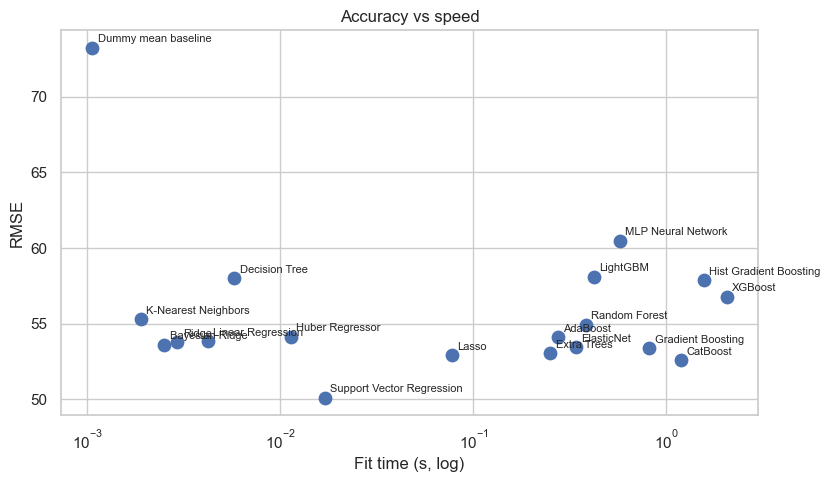

In [94]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(res["FitTime"], res["RMSE"], s=80)
for n, r in res.iterrows():
    if not np.isnan(r["FitTime"]): ax.annotate(n, (r["FitTime"], r["RMSE"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set(xlabel="Fit time (s, log)", ylabel="RMSE", title="Accuracy vs speed"); plt.show()

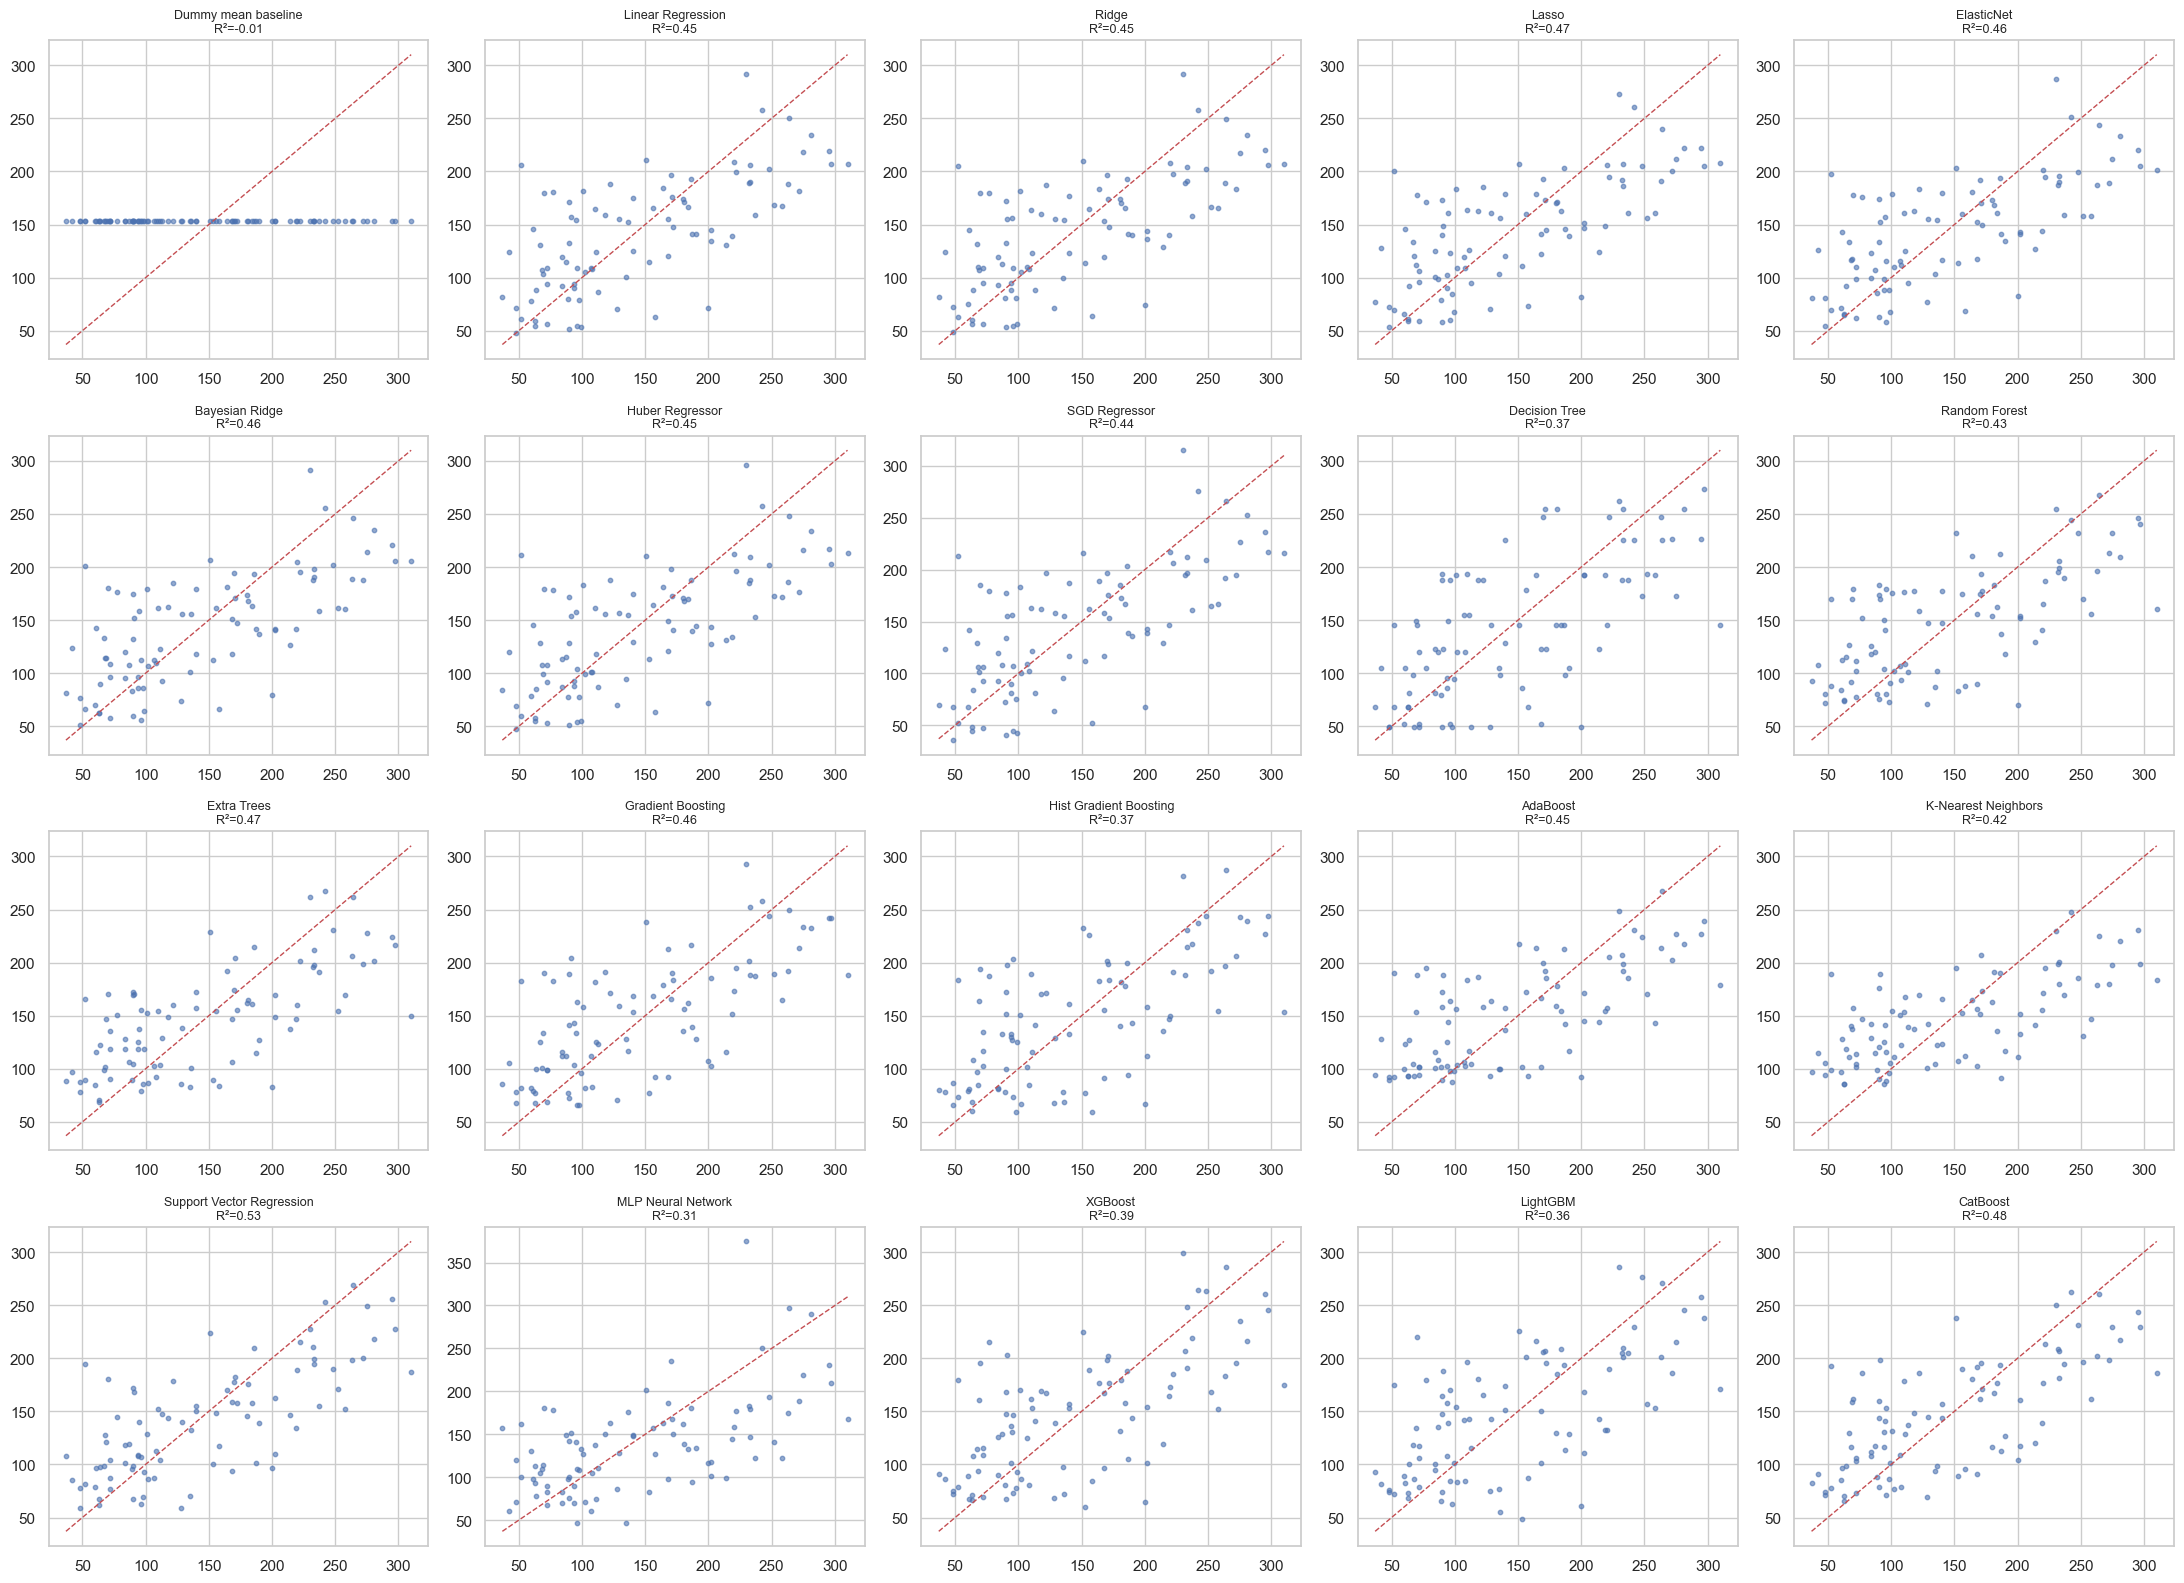

In [95]:
# Actual vs predicted for all 20 models
fig, axs = plt.subplots(4, 5, figsize=(22, 16)); lim = [y_te.min(), y_te.max()]
for ax, (n, p) in zip(axs.ravel(), preds.items()):
    ax.scatter(y_te, p, s=10, alpha=.6); ax.plot(lim, lim, "r--", lw=1)
    ax.set_title(f"{n}\nR²={results[n]['R2']:.2f}", fontsize=9)
plt.tight_layout(); plt.show()